# Sentiment Analysis using BERT-Style Transformer (From Scratch)

**Important:** This notebook does **not** use any pretrained BERT/model weights.

We build a small **BERT-style Transformer Encoder** from scratch and train it for binary sentiment classification on the IMDB movie-review dataset.

**Classes**
- `0` → Negative
- `1` → Positive

This is a practical/college-friendly version designed to run in Google Colab.

In [1]:

import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

if tf.config.list_physical_devices("GPU"):
    print("Using GPU")
else:
    print("Using CPU")

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using GPU


In [2]:

VOCAB_SIZE = 10000
MAX_LEN = 128

(train_x, train_y), (test_x, test_y) = keras.datasets.imdb.load_data(
    num_words=VOCAB_SIZE
)

print("Training samples:", len(train_x))
print("Testing samples:", len(test_x))
print("First review (integer IDs):", train_x[0][:20])
print("First label:", train_y[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training samples: 25000
Testing samples: 25000
First review (integer IDs): [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
First label: 1


## Cell 3 — Pad all reviews to the same length

Transformer batches need a common sequence length.

- Short reviews get `0` padding.
- Long reviews are truncated to `MAX_LEN = 128`.

We use **post-padding/post-truncation** so that the beginning of a review stays intact.

In [3]:

train_x = keras.utils.pad_sequences(
    train_x,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post",
    value=0
)

test_x = keras.utils.pad_sequences(
    test_x,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post",
    value=0
)

print("Train shape:", train_x.shape)
print("Test shape:", test_x.shape)

Train shape: (25000, 128)
Test shape: (25000, 128)


## Cell 4 — Create a Transformer/BERT-style Encoder block

A Transformer encoder mainly uses:

1. Multi-Head Self-Attention
2. Residual connection + Layer Normalization
3. Feed-Forward Neural Network
4. Another residual connection + Layer Normalization

Unlike the original pretrained BERT workflow, the weights here are **randomly initialized and learned from the IMDB training data**.

In [4]:

class TransformerEncoder(layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, dropout=0.1):
        super().__init__()

        self.attention = layers.MultiHeadAttention(
            num_heads=num_heads,
            key_dim=embed_dim // num_heads
        )

        self.ffn = keras.Sequential([
            layers.Dense(ff_dim, activation="gelu"),
            layers.Dense(embed_dim)
        ])

        self.layernorm1 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = layers.LayerNormalization(epsilon=1e-6)

        self.dropout1 = layers.Dropout(dropout)
        self.dropout2 = layers.Dropout(dropout)

    def call(self, inputs, training=False, attention_mask=None):
        attention_output = self.attention(
            inputs,
            inputs,
            attention_mask=attention_mask,
            training=training
        )

        attention_output = self.dropout1(
            attention_output,
            training=training
        )

        out1 = self.layernorm1(inputs + attention_output)

        ffn_output = self.ffn(out1, training=training)
        ffn_output = self.dropout2(
            ffn_output,
            training=training
        )

        return self.layernorm2(out1 + ffn_output)

## Cell 5 — Token + Position Embedding

A Transformer does not automatically know word order.

So we learn:

- **Token embeddings** → meaning/representation of each word ID
- **Position embeddings** → position 0, 1, 2, ... in the review

These embeddings are trained from scratch.

In [5]:

class TokenAndPositionEmbedding(layers.Layer):
    def __init__(self, vocab_size, max_len, embed_dim):
        super().__init__()

        self.token_embedding = layers.Embedding(
            input_dim=vocab_size,
            output_dim=embed_dim,
            mask_zero=True
        )

        self.position_embedding = layers.Embedding(
            input_dim=max_len,
            output_dim=embed_dim
        )

    def call(self, x):
        seq_len = tf.shape(x)[-1]
        positions = tf.range(start=0, limit=seq_len, delta=1)

        token_embeddings = self.token_embedding(x)
        position_embeddings = self.position_embedding(positions)

        return token_embeddings + position_embeddings

## Cell 6 — Build the complete BERT-style sentiment model

Architecture:

`Input IDs → Token+Position Embedding → Transformer Encoder × 2 → Global Average Pooling → Dense → Sigmoid`

The final sigmoid gives a value between 0 and 1:

- `< 0.5` → Negative
- `≥ 0.5` → Positive

In [7]:
EMBED_DIM = 128
NUM_HEADS = 4
FF_DIM = 256
NUM_BLOCKS = 2
DROPOUT = 0.2

inputs = keras.Input(
    shape=(MAX_LEN,),
    dtype=tf.int32
)

x = TokenAndPositionEmbedding(
    VOCAB_SIZE,
    MAX_LEN,
    EMBED_DIM
)(inputs)

for _ in range(NUM_BLOCKS):
    x = TransformerEncoder(
        EMBED_DIM,
        NUM_HEADS,
        FF_DIM,
        DROPOUT
    )(x)

x = layers.GlobalAveragePooling1D()(x)

x = layers.Dropout(DROPOUT)(x)

x = layers.Dense(
    64,
    activation="relu"
)(x)

x = layers.Dropout(DROPOUT)(x)

outputs = layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = keras.Model(
    inputs=inputs,
    outputs=outputs
)

model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ token_and_position_embedding_1  │ (None, 128, 128)       │     1,296,384 │
│ (TokenAndPositionEmbedding)     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder_2           │ (None, 128, 128)       │       132,480 │
│ (TransformerEncoder)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ transformer_encoder_3           │ (None, 128, 128)       │       132,480 │
│ (TransformerEncoder)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,569,665 (5.99 MB)

 Trainable params: 1,569,665 (5.99 MB)

 Non-trainable params: 0 (0.00 B)

## Cell 7 — Compile the model

We use:

- **Adam** optimizer
- **Binary cross-entropy** loss because this is a two-class problem
- **Accuracy** as the main metric

In [8]:

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=2e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


## Cell 8 — Train the model

For a quick Colab practical, start with **3 epochs**.

The model learns all Transformer, embedding, and classifier weights from scratch.

In [9]:

EPOCHS = 3
BATCH_SIZE = 64

history = model.fit(
    train_x,
    train_y,
    validation_split=0.1,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

Epoch 1/3
352/352 ━━━━━━━━━━━━━━━━━━━━ 29s 44ms/step - accuracy: 0.7301 - loss: 0.5091 - val_accuracy: 0.8232 - val_loss: 0.3882
Epoch 2/3
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.8762 - loss: 0.3032 - val_accuracy: 0.8488 - val_loss: 0.3658
Epoch 3/3
352/352 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - accuracy: 0.9075 - loss: 0.2347 - val_accuracy: 0.8552 - val_loss: 0.3737


## Cell 9 — Evaluate on unseen test data

In [10]:

test_loss, test_accuracy = model.evaluate(
    test_x,
    test_y,
    batch_size=BATCH_SIZE,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

391/391 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8213 - loss: 0.4217
Test Loss: 0.4217
Test Accuracy: 82.13%


## Cell 10 — Plot training and validation accuracy

This helps us see whether the model is learning during training.

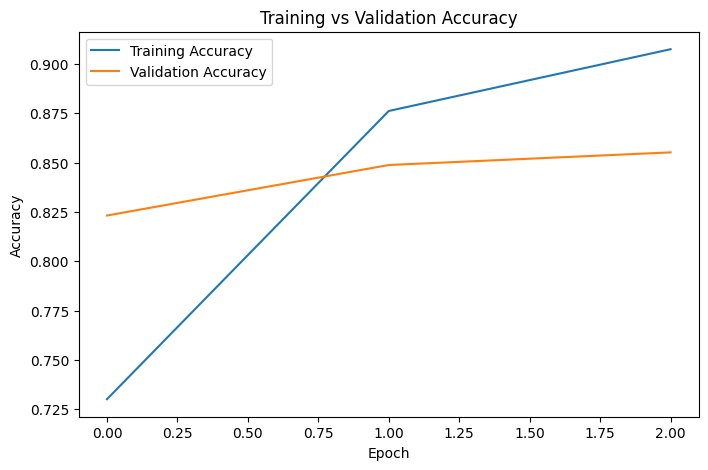

In [11]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.show()

## Cell 11 — Plot training and validation loss

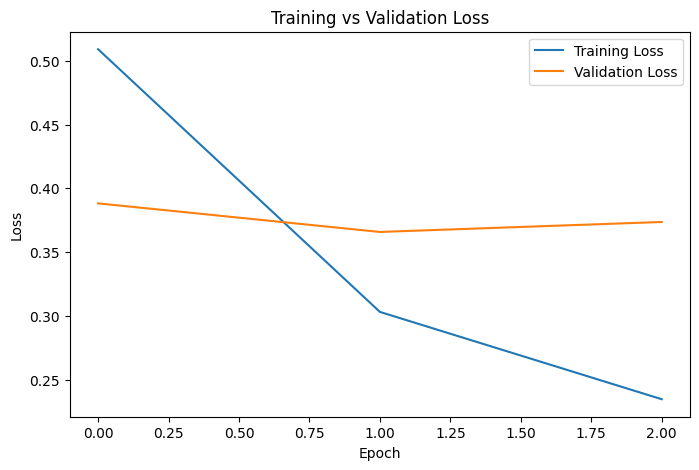

In [12]:

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

## Cell 12 — Convert normal text into IMDB integer IDs

The Keras IMDB dataset stores reviews as integer IDs. This helper reconstructs the words and converts a new review into the same integer-ID format.

Special IDs used by Keras IMDB:
- `0` → padding
- `1` → start token
- `2` → unknown word
- actual dictionary words start from higher IDs

In [16]:
word_index = keras.datasets.imdb.get_word_index()

# Convert word -> integer ID
word_to_id = {word: (idx + 3) for word, idx in word_index.items()}

# Reserved tokens
word_to_id["<PAD>"] = 0
word_to_id["<START>"] = 1
word_to_id["<UNK>"] = 2


def encode_review(text):
    # Convert text to lowercase and split into words
    words = text.lower().split()

    # Start token
    ids = [1]

    for word in words:
        # Remove punctuation
        word = word.strip(".,!?;:\"'()[]{}")

        # If word is not in vocabulary, use <UNK> = 2
        ids.append(word_to_id.get(word, 2))

    # Make sequence length MAX_LEN
    return keras.utils.pad_sequences(
        [ids],
        maxlen=MAX_LEN,
        padding="post",
        truncating="post",
        value=0
    )

print("Review encoder ready!")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
Review encoder ready!


## Cell 13 — Predict sentiment for a custom review

In [17]:

def predict_sentiment(review):
    encoded = encode_review(review)
    probability = float(model.predict(encoded, verbose=0)[0][0])

    if probability >= 0.5:
        sentiment = "Positive"
        confidence = probability
    else:
        sentiment = "Negative"
        confidence = 1 - probability

    return sentiment, confidence

review = "This movie was absolutely fantastic and I really enjoyed it."

sentiment, confidence = predict_sentiment(review)

print("Review:", review)
print("Sentiment:", sentiment)
print("Confidence:", f"{confidence * 100:.2f}%")

Review: This movie was absolutely fantastic and I really enjoyed it.
Sentiment: Positive
Confidence: 99.84%


## Cell 14 — Test multiple custom reviews

In [18]:

reviews = [
    "I loved this movie. The acting was excellent.",
    "This was boring and a complete waste of time.",
    "The story was amazing and the characters were wonderful.",
    "I hated this movie. It was terrible."
]

for review in reviews:
    sentiment, confidence = predict_sentiment(review)

    print("Review:", review)
    print("Sentiment:", sentiment)
    print("Confidence:", f"{confidence * 100:.2f}%")
    print("-" * 80)

Review: I loved this movie. The acting was excellent.
Sentiment: Positive
Confidence: 99.85%
--------------------------------------------------------------------------------
Review: This was boring and a complete waste of time.
Sentiment: Negative
Confidence: 99.71%
--------------------------------------------------------------------------------
Review: The story was amazing and the characters were wonderful.
Sentiment: Positive
Confidence: 99.86%
--------------------------------------------------------------------------------
Review: I hated this movie. It was terrible.
Sentiment: Negative
Confidence: 99.51%
--------------------------------------------------------------------------------


## Cell 15 — Save the trained model

This saves the model architecture and learned weights so it can be reused later without retraining in the same way.

In [19]:

model.save("sentiment_transformer_from_scratch.keras")

print("Model saved as: sentiment_transformer_from_scratch.keras")

Model saved as: sentiment_transformer_from_scratch.keras


# Final Workflow

**IMDB Reviews → Integer IDs → Token Embedding + Position Embedding → Transformer Encoder Blocks → Pooling → Dense Layer → Positive/Negative**

### Important viva points

- **Pretrained model used?** No.
- **BERT weights used?** No. All model weights are learned from scratch.
- **Why Transformer?** Self-attention lets the model learn relationships between words in a sequence.
- **Why positional embedding?** Attention alone does not provide word-order information.
- **Why binary cross-entropy?** There are two sentiment classes.
- **Output?** Sigmoid probability between 0 and 1.
- **0 = Negative, 1 = Positive.**

> Note: This is a **BERT-style Transformer encoder trained from scratch**, not the original `bert-base-uncased` pretrained BERT checkpoint.